In [7]:
import pandas as pd

df = pd.read_csv("Envoy_Air.csv")

print(df.shape)


(1072778, 61)


Valeurs manquantes

In [9]:
manquantes = df.isnull().sum()

resultat = pd.DataFrame({
    "Valeurs manquantes": manquantes,
    "Pourcentage (%)": (manquantes / len(df) * 100).round(2)
})

display(
    resultat[resultat["Valeurs manquantes"] > 0]
    .sort_values("Pourcentage (%)", ascending=False)
)

,Valeurs manquantes,Pourcentage (%)
ArrivalDelayGroups,38799,3.62
ArrDel15,38799,3.62
ArrDelayMinutes,38799,3.62
AirTime,38799,3.62
ActualElapsedTime,38799,3.62
ArrDelay,38799,3.62
ArrTime,36389,3.39
TaxiIn,36389,3.39
WheelsOn,36389,3.39
WheelsOff,35857,3.34


Vérification des doublons

In [11]:
colonnes_dupliquees = []

for i in range(len(df.columns)):
    for j in range(i + 1, len(df.columns)):
        if df.iloc[:, i].equals(df.iloc[:, j]):
            colonnes_dupliquees.append(
                (df.columns[i], df.columns[j])
            )

print("Colonnes dupliquées :", colonnes_dupliquees)

Colonnes dupliquées : [('Marketing_Airline_Network', 'IATA_Code_Marketing_Airline'), ('Flight_Number_Marketing_Airline', 'Flight_Number_Operating_Airline'), ('Operating_Airline', 'IATA_Code_Operating_Airline')]


In [ ]:
df = df.loc[:, ~df.T.duplicated()]

Variables avec une seule valeur ou presque

In [12]:
for col in df.columns:
    frequences = df[col].value_counts(normalize=True, dropna=False)

    if len(frequences) <= 1:
        print(f"{col} : une seule valeur")
    elif frequences.iloc[0] >= 0.99:
        print(f"{col} : 99 % ou plus pour une même valeur")

Airline : une seule valeur
Diverted : 99 % ou plus pour une même valeur
Marketing_Airline_Network : une seule valeur
Operated_or_Branded_Code_Share_Partners : une seule valeur
DOT_ID_Marketing_Airline : une seule valeur
IATA_Code_Marketing_Airline : une seule valeur
Operating_Airline : une seule valeur
DOT_ID_Operating_Airline : une seule valeur
IATA_Code_Operating_Airline : une seule valeur
DivAirportLandings : 99 % ou plus pour une même valeur


Distribution des retards

In [13]:
display(df["ArrDel15"].value_counts(dropna=False))

display(
    (df["ArrDel15"].value_counts(normalize=True, dropna=False) * 100)
    .round(2)
)

ArrDel15
0.0    854156
1.0    179823
NaN     38799
Name: count, dtype: int64

ArrDel15
0.0    79.62
1.0    16.76
NaN     3.62
Name: proportion, dtype: float64

Valeurs aberrantes

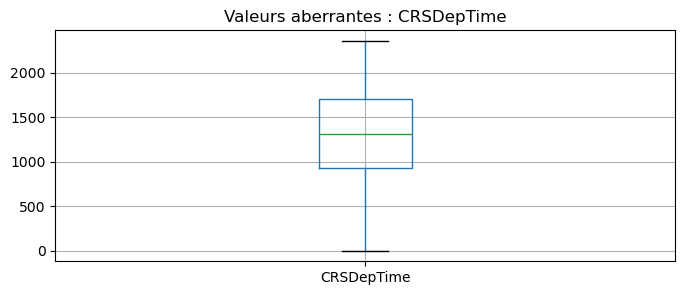

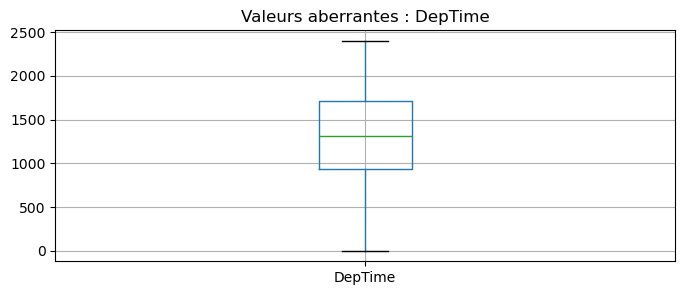

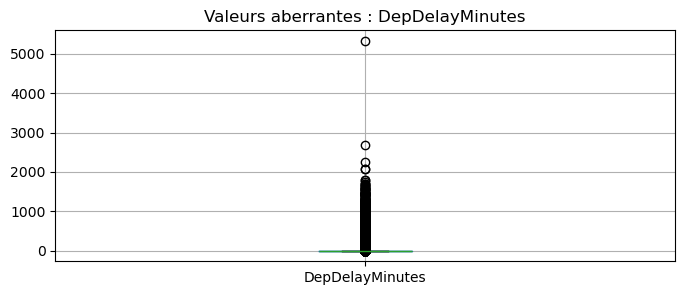

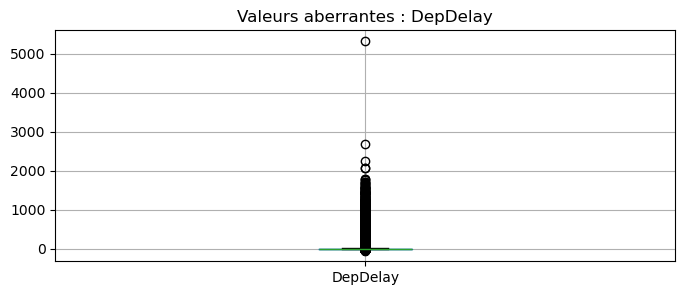

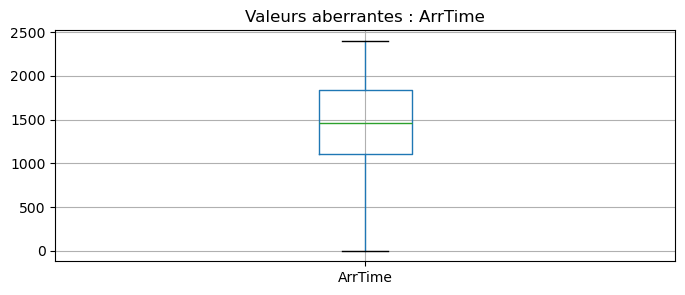

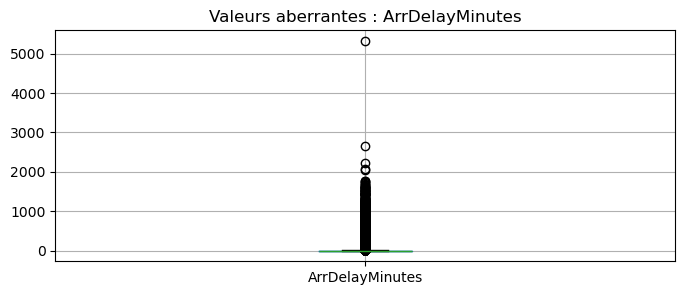

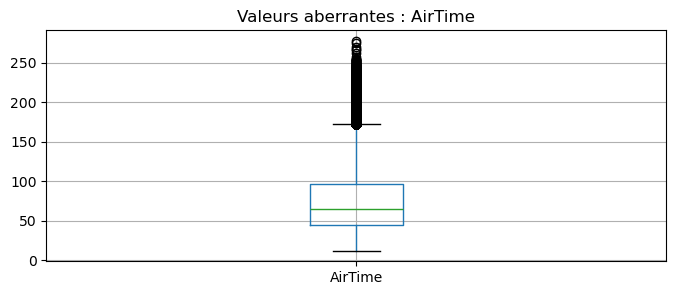

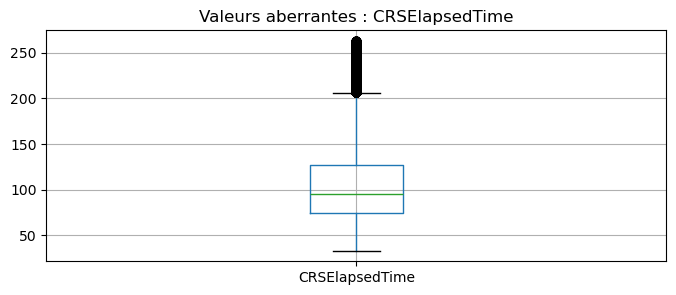

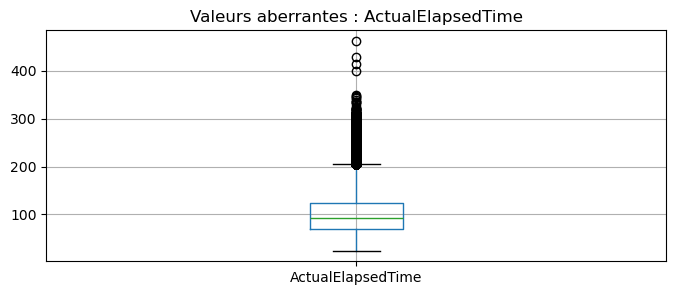

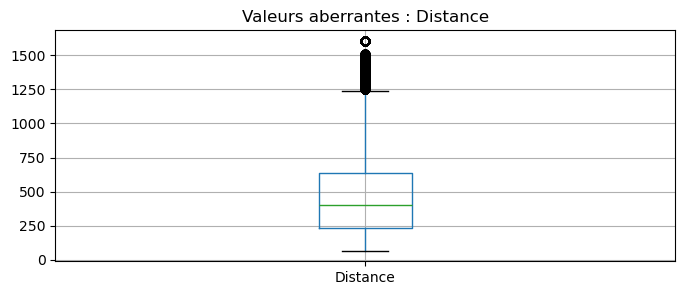

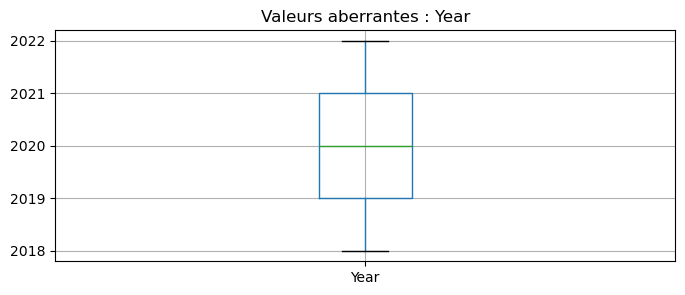

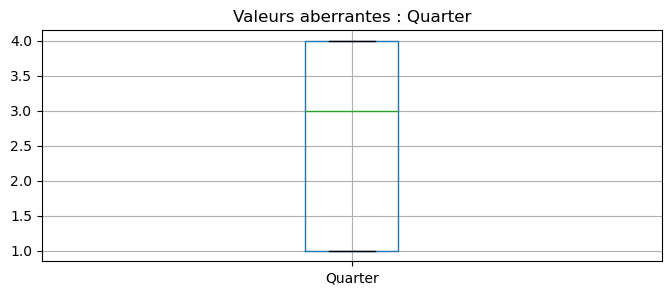

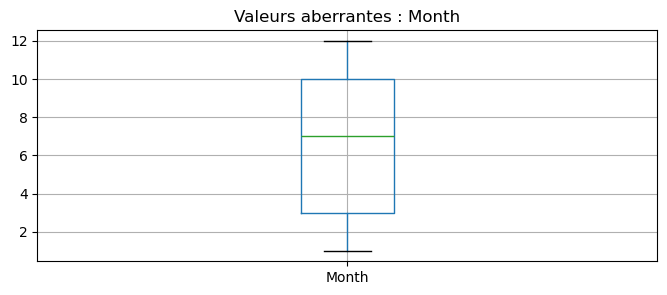

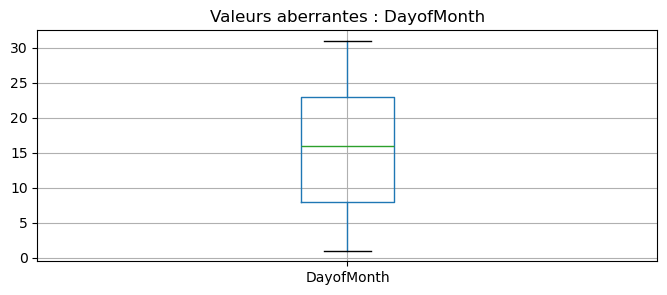

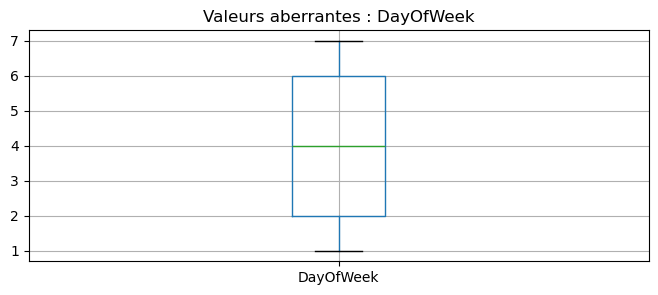

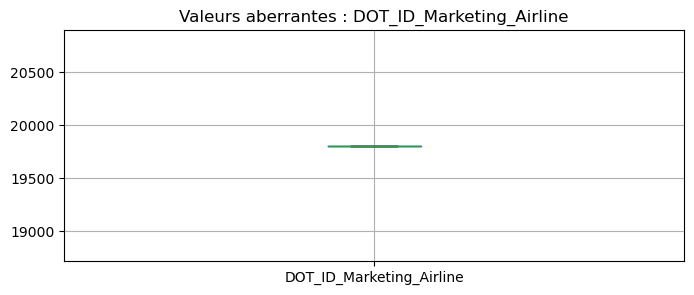

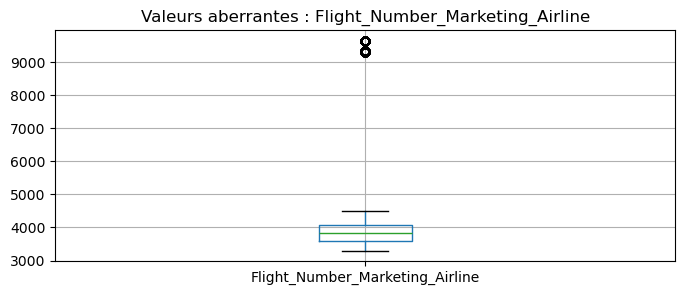

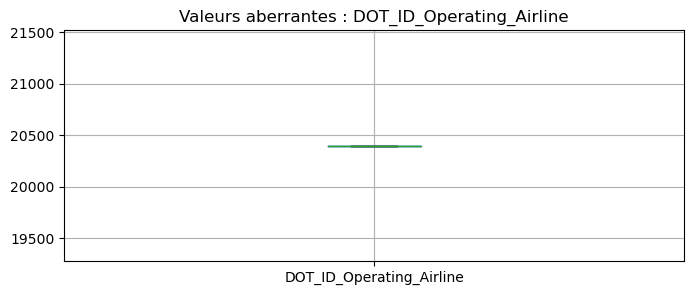

In [ ]:
import matplotlib.pyplot as plt

colonnes_numeriques = df.select_dtypes(include="number").columns

for col in colonnes_numeriques:
    plt.figure(figsize=(8, 3))
    df.boxplot(column=col)
    plt.title(f"Valeurs aberrantes : {col}")
    plt.show()

Corrélation entre variables numériques

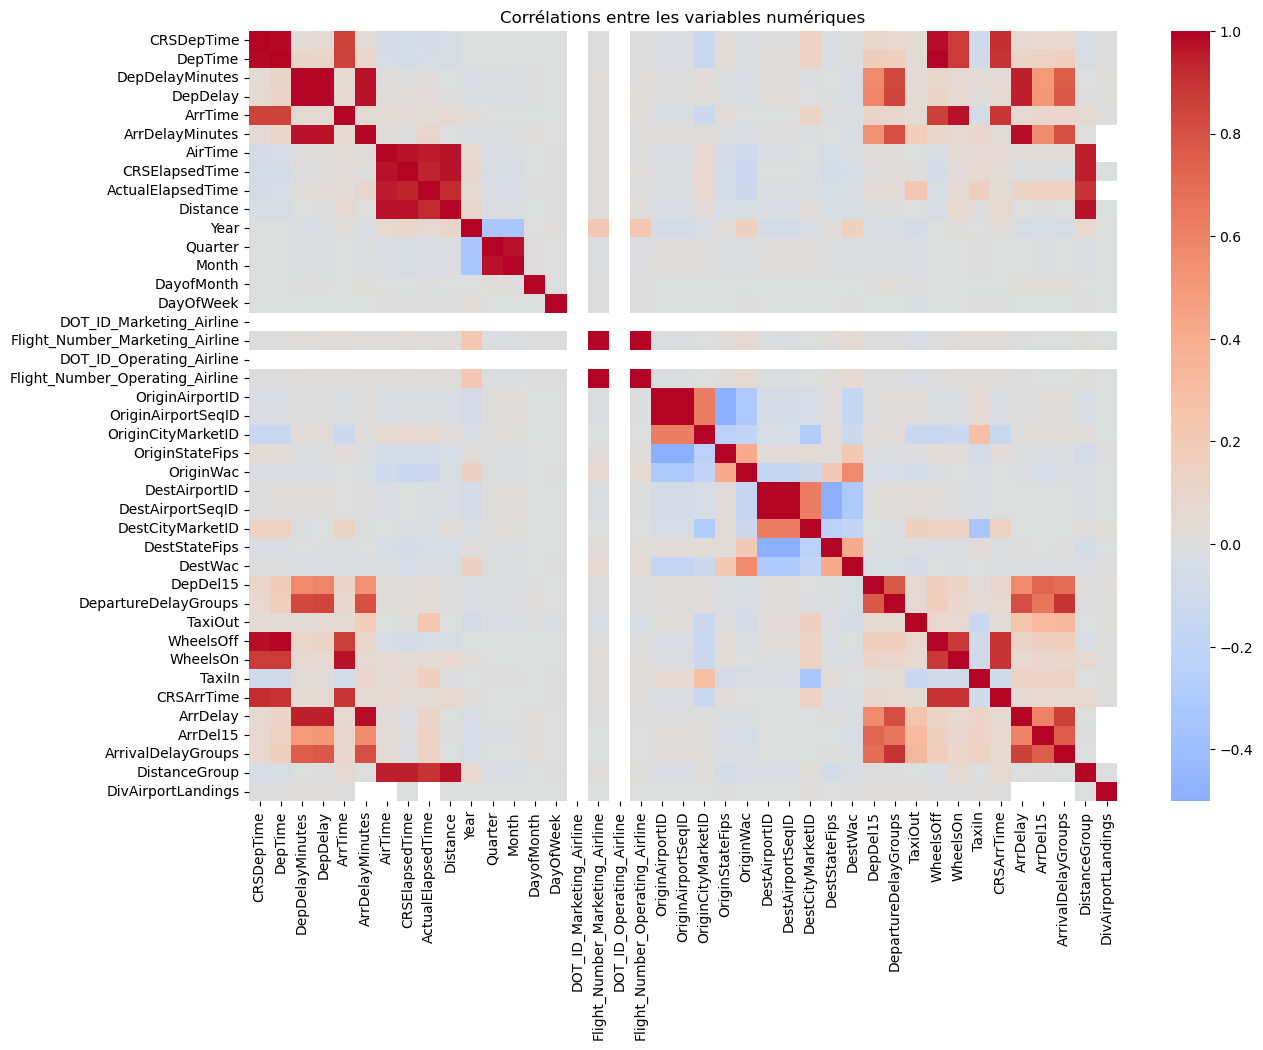

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt

correlations = df.select_dtypes(include="number").corr()

plt.figure(figsize=(14, 10))
sns.heatmap(correlations, cmap="coolwarm", center=0)
plt.title("Corrélations entre les variables numériques")
plt.show()

Vérifier les catégories des variables importantes

In [16]:
for col in ["Airline", "Origin", "Dest", "DepTimeBlk", "ArrTimeBlk"]:
    if col in df.columns:
        print(f"\n--- {col} ---")
        print("Nombre de catégories :", df[col].nunique())
        display(df[col].value_counts().head(10))


--- Airline ---
Nombre de catégories : 1


Airline
Envoy Air    1072778
Name: count, dtype: int64


--- Origin ---
Nombre de catégories : 190


Origin
DFW    238861
ORD    195608
MIA     43267
LGA     20513
SGF     16778
XNA     15621
CVG     15524
CMH     14252
CLT     13601
LIT     13261
Name: count, dtype: int64


--- Dest ---
Nombre de catégories : 190


Dest
DFW    238780
ORD    195536
MIA     43256
LGA     20511
SGF     16786
XNA     15625
CVG     15527
CMH     14252
CLT     13598
LIT     13265
Name: count, dtype: int64


--- DepTimeBlk ---
Nombre de catégories : 19


DepTimeBlk
1200-1259    89558
1000-1059    88985
0800-0859    82420
0600-0659    77968
1600-1659    77081
1800-1859    74660
1400-1459    73949
1500-1559    66200
0700-0759    60563
1300-1359    58489
Name: count, dtype: int64


--- ArrTimeBlk ---
Nombre de catégories : 19


ArrTimeBlk
1700-1759    89127
1100-1159    88666
1500-1559    81997
1900-1959    79170
0900-0959    77553
1400-1459    69189
1200-1259    66221
0700-0759    64376
1300-1359    63176
1600-1659    58276
Name: count, dtype: int64